# World Happiness AI Lab — Exploratory Analysis Notebook

A reproducible walk-through of the core analysis using the project modules in `src/`. All numbers are computed from the World Happiness Report files in `data/raw/`.

> Life Ladder = national average of *reported* life evaluations (0–10). Every relationship below is an association, not a causal effect.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 3)
from src.data_loader import load_bundle
from src.config import INDICATORS, TARGET, SHORT_LABELS
b = load_bundle(use_cache=False)
b.inventory()

,file,kind,edition,rows,countries,years,valid,used_for
0,kaggle_unsdsn/2015.csv,edition_contrib,2015.0,158,158,2014–2014,True,edition archive
1,kaggle_unsdsn/2016.csv,edition_contrib,2016.0,157,157,2015–2015,True,edition archive
2,kaggle_unsdsn/2017.csv,edition_contrib,2017.0,155,155,2016–2016,True,edition archive
3,kaggle_unsdsn/2018.csv,edition_contrib,2018.0,156,156,2017–2017,True,edition archive
4,kaggle_unsdsn/2019.csv,edition_contrib,2019.0,156,156,2018–2018,True,edition archive
5,whr_official/WHR20_Data_Figure_2.1.xls,edition_raw,2020.0,153,153,2019–2019,True,edition archive
6,whr_official/WHR21_Data_Figure_2.1.xls,edition_raw,2021.0,149,149,2020–2020,True,edition archive
7,whr_official/WHR22_Data_Figure_2.1.xls,edition_contrib,2022.0,146,146,2021–2021,True,edition archive
8,whr_official/WHR23_Data_Figure_2.1.xls,edition_raw,2023.0,137,137,2022–2022,True,edition archive
9,whr_official/WHR24_Data_Figure_2.1.xls,edition_contrib,2024.0,143,143,2023–2023,True,edition archive


## 1. Dataset overview

In [2]:
from src.eda import dataset_overview, ranking_overview
pd.Series(dataset_overview(b.panel)), pd.Series(ranking_overview(b.rankings))

(observations                      2199
 countries                          165
 years                               18
 year_min                          2005
 year_max                          2022
 features                             8
 mean_score                       5.479
 median_score                     5.432
 std_score                        1.126
 max_score                        8.019
 max_country                    Denmark
 max_year                          2005
 min_score                        1.281
 min_country                Afghanistan
 min_year                          2022
 missing_cells                      351
 missing_pct                      1.774
 duplicate_country_years              0
 dtype: object,
 year                  2025
 edition               2026
 countries              147
 mean_score            5.65
 max_score            7.764
 max_country        Finland
 min_score            1.446
 min_country    Afghanistan
 dtype: object)

In [3]:
b.panel.head()

,country,iso3,year,life_ladder,log_gdp_per_capita,social_support,healthy_life_expectancy,freedom,generosity,perceptions_of_corruption,positive_affect,negative_affect,source,region
0,Afghanistan,AFG,2008,3.724,7.350,0.451,50.5,0.718,0.168,0.882,0.414,0.258,WHR2023_DataForTable2.1_panel.csv,South Asia
1,Afghanistan,AFG,2009,4.402,7.509,0.552,50.8,0.679,0.191,0.850,0.481,0.237,WHR2023_DataForTable2.1_panel.csv,South Asia
2,Afghanistan,AFG,2010,4.758,7.614,0.539,51.1,0.600,0.121,0.707,0.517,0.275,WHR2023_DataForTable2.1_panel.csv,South Asia
3,Afghanistan,AFG,2011,3.832,7.581,0.521,51.4,0.496,0.164,0.731,0.480,0.267,WHR2023_DataForTable2.1_panel.csv,South Asia
4,Afghanistan,AFG,2012,3.783,7.661,0.521,51.7,0.531,0.238,0.776,0.614,0.268,WHR2023_DataForTable2.1_panel.csv,South Asia


## 2. Distribution of Life Ladder

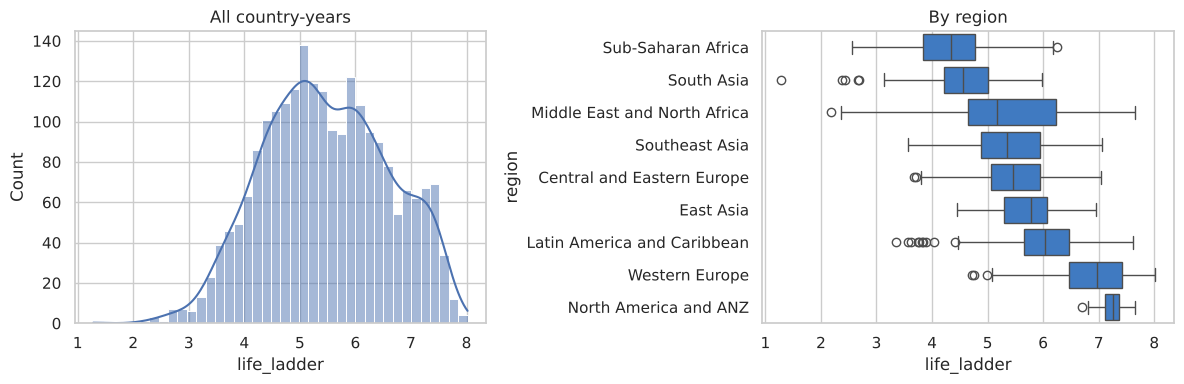

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(b.panel[TARGET], bins=40, kde=True, ax=ax[0])
ax[0].set_title('All country-years')
order = b.panel.groupby('region')[TARGET].median().sort_values().index
sns.boxplot(data=b.panel, y='region', x=TARGET, order=order, ax=ax[1], color='#2a78d6')
ax[1].set_title('By region'); plt.tight_layout()

## 3. Correlations

In [5]:
from src.statistical_analysis import correlation_tests
correlation_tests(b.panel, TARGET, INDICATORS + ['positive_affect', 'negative_affect'])[['feature','n','pearson_r','pearson_ci_low','pearson_ci_high','spearman_rho','strength']]

,feature,n,pearson_r,pearson_ci_low,pearson_ci_high,spearman_rho,strength
0,log_gdp_per_capita,2179,0.785,0.768,0.800,0.804,strong
1,healthy_life_expectancy,2143,0.723,0.702,0.743,0.765,strong
2,social_support,2186,0.722,0.701,0.741,0.762,strong
3,freedom,2166,0.534,0.504,0.564,0.545,moderate–strong
4,positive_affect,2175,0.518,0.487,0.548,0.514,moderate–strong
5,perceptions_of_corruption,2083,-0.431,-0.466,-0.396,-0.327,moderate
6,negative_affect,2183,-0.340,-0.377,-0.302,-0.298,moderate
7,generosity,2126,0.182,0.140,0.222,0.163,weak


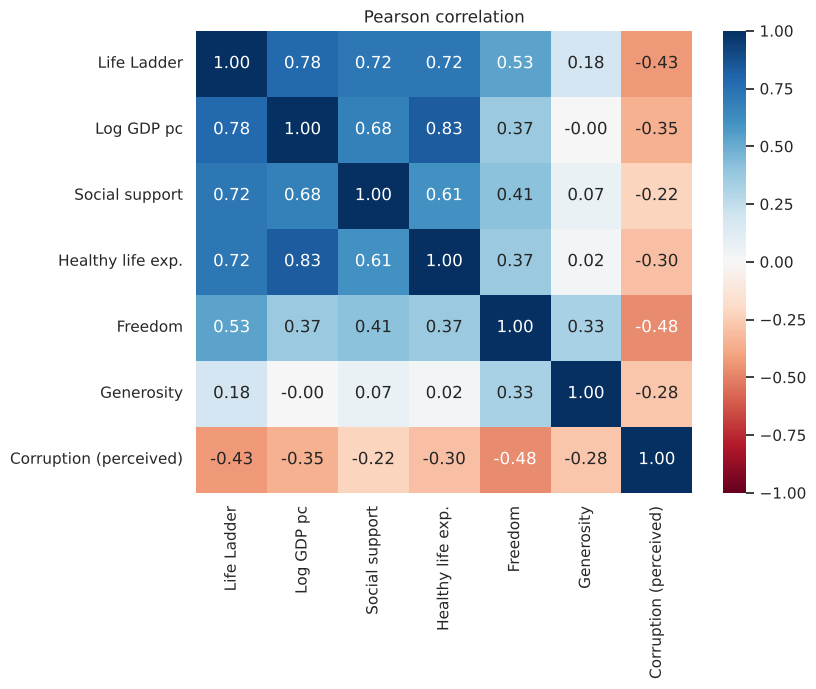

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(b.panel[[TARGET] + INDICATORS].corr().rename(index=SHORT_LABELS, columns=SHORT_LABELS), annot=True, fmt='.2f', cmap='RdBu', vmin=-1, vmax=1)
plt.title('Pearson correlation');

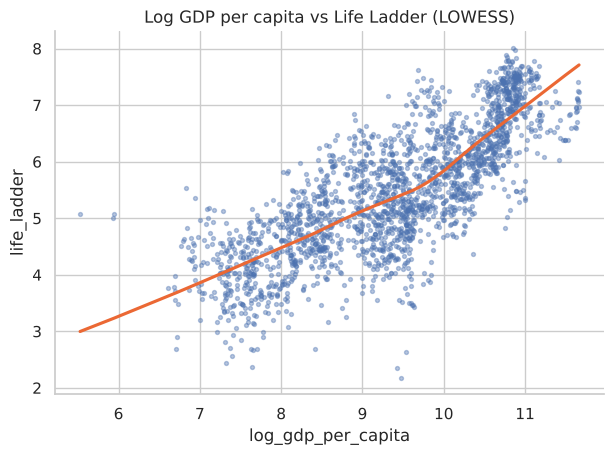

In [7]:
sns.lmplot(data=b.panel, x='log_gdp_per_capita', y=TARGET, scatter_kws={'s': 8, 'alpha': .4}, height=4.5, aspect=1.4, lowess=True, line_kws={'color': '#eb6834'})
plt.title('Log GDP per capita vs Life Ladder (LOWESS)');

## 4. Multiple regression with country-clustered standard errors

In [8]:
from src.statistical_analysis import ols_regression
r = ols_regression(b.panel, TARGET, INDICATORS)
print(f"R² = {r['r2']:.3f}, adj. R² = {r['adj_r2']:.3f}, n = {r['n']}")
r['table'][['term','coef','std_err','cluster_std_err','cluster_p_value','cluster_ci_low','cluster_ci_high']]

R² = 0.753, adj. R² = 0.752, n = 1962


,term,coef,std_err,cluster_std_err,cluster_p_value,cluster_ci_low,cluster_ci_high
0,const,-2.045,0.169,0.494,3.467e-05,-3.014,-1.077
1,log_gdp_per_capita,0.354,0.024,0.068,2.208e-07,0.220,0.488
2,social_support,2.582,0.150,0.351,1.917e-13,1.894,3.270
3,healthy_life_expectancy,0.028,0.004,0.011,7.945e-03,0.007,0.049
4,freedom,1.186,0.115,0.275,1.656e-05,0.646,1.725
5,generosity,0.557,0.087,0.252,2.698e-02,0.063,1.050
6,perceptions_of_corruption,-0.725,0.083,0.257,4.782e-03,-1.229,-0.221


In [9]:
for m in r['diagnostics']['interpretation']: print('-', m)
r['diagnostics']['vif']

- Breusch–Pagan p = 1.94e-17: evidence of heteroscedasticity → rely on HC3 / clustered SEs.
- Jarque–Bera p = 1.72e-10: residuals deviate from normality (with large n, inference on coefficients remains approximately valid).
- Durbin–Watson = 0.59: positive autocorrelation, expected because rows are sorted country-year → clustered SEs account for within-country dependence.
- Max VIF = 4.56: multicollinearity is moderate.
- Ramsey RESET p = 8.7e-30: some evidence of non-linearity / omitted terms.


,feature,vif
0,log_gdp_per_capita,4.557
1,social_support,2.095
2,healthy_life_expectancy,3.582
3,freedom,1.581
4,generosity,1.194
5,perceptions_of_corruption,1.450


## 5. Missing values and outliers

In [10]:
from src.preprocessing import missing_summary, outlier_summary
missing_summary(b.panel, INDICATORS + ['positive_affect', 'negative_affect'])

,missing,missing_pct,non_missing
perceptions_of_corruption,116,5.28,2083
generosity,73,3.32,2126
healthy_life_expectancy,56,2.55,2143
freedom,33,1.50,2166
positive_affect,24,1.09,2175
log_gdp_per_capita,20,0.91,2179
negative_affect,16,0.73,2183
social_support,13,0.59,2186


In [11]:
outlier_summary(b.panel)

,variable,n_flagged,countries,pct_flagged
5,perceptions_of_corruption,184,"Australia, Canada, Denmark, Estonia, Finland, ...",8.37
6,social_support,50,"Afghanistan, Bangladesh, Benin, Burundi, Centr...",2.27
1,generosity,37,"Cambodia, Gambia, Indonesia, Laos, Malta, Myan...",1.68
2,healthy_life_expectancy,18,"Central African Republic, Eswatini, Haiti, Les...",0.82
0,freedom,14,"Bosnia and Herzegovina, Burundi, Chad, Cuba, H...",0.64
4,log_gdp_per_capita,1,Venezuela,0.05
3,life_ladder,1,Afghanistan,0.05


## 6. Machine-learning results (from `python -m src.train`)

In [12]:
from src.model_manager import load_results
res = load_results()
rows = [{'question': s, 'model': m['name'], 'val_rmse': m['val']['rmse'], 'test_rmse': m['test']['rmse'], 'test_r2': m['test']['r2']}
        for s, e in res['experiments'].items() for m in e['models'].values()]
pd.DataFrame(rows).pivot(index='model', columns='question', values='test_rmse').round(3)

question,group,random,temporal
model,,,
Decision Tree,0.636,0.570,0.658
Gradient Boosting,0.537,0.503,0.578
Lasso Regression,0.573,0.606,0.564
Linear Regression,0.573,0.606,0.564
Random Forest,0.521,0.488,0.568
Ridge Regression,0.571,0.606,0.564
XGBoost,0.517,0.489,0.569


In [13]:
cv = pd.DataFrame(res['cv_comparison']).pivot(index='model', columns='strategy', values='rmse_mean')
cv['group_vs_random_%'] = (cv['group']/cv['random']-1)*100
cv.round(3)

strategy,group,random,temporal,group_vs_random_%
model,,,,
Decision Tree,0.650,0.564,0.590,15.374
Gradient Boosting,0.564,0.517,0.525,9.079
Lasso Regression,0.588,0.572,0.560,2.791
Linear Regression,0.588,0.572,0.560,2.791
Random Forest,0.565,0.506,0.527,11.713
Ridge Regression,0.587,0.572,0.560,2.722
XGBoost,0.563,0.507,0.521,10.890


In [14]:
res['best_model']['name'], res['best_model']['test'], res['conformal']

('Random Forest',
 {'r2': 0.731056635088588,
  'mae': 0.39465886948623413,
  'mse': 0.27125154519752054,
  'rmse': 0.5208181498349693,
  'max_error': 1.7398967923368112,
  'bias': -0.03657017168303191,
  'n': 303,
  'adj_r2': 0.7256050803944378},
 {'method': 'Split-conformal (country-grouped)',
  'coverage_target': 0.9,
  'q_cv': 0.9374943494488726,
  'q_split': 0.8762348828470792,
  'empirical_test_coverage_split': 0.9174917491749175,
  'empirical_oof_coverage_cv': 0.9004092769440655,
  'n_calibration': 319,
  'n_test': 303})

## 7. Clustering

In [15]:
from src.clustering import run_clustering
cl = run_clustering(b.panel)
print(cl.k_reason)
cl.cluster_summary[['cluster','name','n_countries', TARGET, 'example_countries']]

k = 3 has the best average rank across silhouette (↑), Davies–Bouldin (↓) and Calinski–Harabasz (↑) among solutions whose smallest cluster has ≥ 5 countries.


,cluster,name,n_countries,life_ladder,example_countries
0,0,Very high indicators · low perceived corruptio...,22,7.010,"Finland, Denmark, Iceland, Netherlands, Sweden"
1,1,Mid-range indicators · close to global average,70,5.812,"Israel, United States, Czechia, Lithuania, Slo..."
2,2,"Low indicators · shorter healthy lives, weaker...",42,4.294,"Nepal, Congo (Brazzaville), Venezuela, Laos, G..."


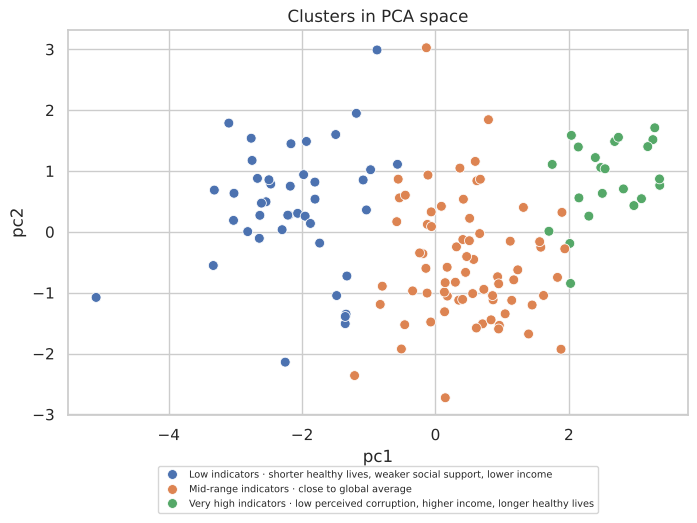

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=cl.profiles, x='pc1', y='pc2', hue='cluster_name', s=50, ax=ax)
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.set_title('Clusters in PCA space');

## 8. Automated insights

In [17]:
from src.insight_engine import generate_insights
from src.feature_engineering import engineer_panel
for i in generate_insights(b.panel, engineer_panel(b.panel), b.rankings, b.panel_source, b.rankings_source, res, cl)[:8]:
    print(f'• {i.title}: {i.text}\n')

• Highest reported life evaluations: In the WHR 2026 ranking (survey years 2023–2025), the highest 3-year average ladder scores are: Finland (7.764), Iceland (7.540), Denmark (7.539) — out of 147 countries ranked.

• Lowest reported life evaluations: The lowest scores in the same ranking are: Afghanistan (1.446), Sierra Leone (3.251), Malawi (3.284). The gap between first and last place is 6.32 points on the 0–10 ladder.

• Ranking uncertainty at the top: 0 other countries have 95% confidence intervals that overlap with Finland's, so small rank differences near the top are not statistically meaningful.

• Largest long-run improvement: Among 141 countries ranked in both WHR 2012 and WHR 2026, Serbia improved the most: 4.56 → 6.69 (+2.13), moving +88 places.

• Largest long-run decline: Afghanistan declined the most: 4.26 → 1.45 (-2.81), moving -16 places.

• Largest single-year rise: Bahrain recorded the largest year-over-year increase in the annual panel: +1.66 points from 2012 to 2013